# Main tutorial: F.E. Walter weather to daily operation

Follow the current 2016 example: **Rule-based**, **LLM with available
information**, and **LLM with retrieved knowledge**. All methods share the
accepted hydrology, physical initial state and routing. The model is selected
inside `current/models.yaml`; the experiment filename identifies the method.

This notebook reads committed annual results and recorded provider messages.
It makes no model request and runs no hydrology or reservoir simulation.

![HydroOpsLM coupling concept](../docs/figures/hydrocnhs-coupling-framework-en.png)

[Configuration walkthrough](fe_walter.md) ·
[Current annual comparison](../examples/fe_walter/coupled/README.md#verified-2016-results)

## Setup

The builder blocks socket and urllib access. Tables and plots below are
recreated from saved files, including the independent Anik engine comparison.

In [1]:
from pathlib import Path
import html, json, re, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/hydrocnhs").is_dir())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from llm_reservoir_agent.workflow import load_settings
from llm_reservoir_agent.verification import verify_run
from tutorials.inspect_decision_flow import load_decision_flow

class ReadableText:
    """Render preserved text as a readable notebook block."""
    def __init__(self, title, text):
        self.title, self.text = title, text
    def _repr_markdown_(self):
        fence = "`" * max(4, 1 + max((len(run) for run in re.findall(r"`+", self.text)), default=0))
        return f"#### {self.title}\n\n{fence}text\n{self.text}\n{fence}"
    def _repr_html_(self):
        return f'<h4>{html.escape(self.title)}</h4><pre class="prompt-text">{html.escape(self.text)}</pre>'

def jsonl(path):
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines()]

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.figsize": (9, 4.8), "axes.grid": True, "figure.dpi": 120})

## 1. Read the shared physical case and accepted inflow

The native weather model covers 1989–2025 and supplies the selected 366 days of
2016. Initial storage **2,457,848.279729185 m³ (1,992.61 acre-ft)** is an
assumption. Reservoir losses are zero; downstream `UH=[1.0]` is identity routing.

![F.E. Walter catchment](../docs/figures/fe-walter-catchment.png)

In [2]:
coupled = ROOT / "examples/fe_walter/coupled"
annual = coupled / "outputs/gemma4_2016_comparison"
summary = json.loads((annual / "summary.json").read_text(encoding="utf-8"))
daily = pd.read_csv(annual / "daily.csv")
case = json.loads((coupled / "reservoirs.json").read_text(encoding="utf-8"))
physical = case["network"]["reservoirs"]["FEWalter"]["physical"]
labels = {"rule": "Rule-based", "llm_available": "LLM with available information",
          "llm_knowledge": "LLM with retrieved knowledge"}
display(pd.DataFrame([{"field": key, "value": physical[key]}
                      for key in ("initial_storage_m3", "capacity_m3", "minimum_release_cms",
                                  "maximum_release_cms", "dt_seconds")]))
inflow = daily.loc[(daily["engine"] == "framework") & (daily["method"] == "llm_available"),
                   ["date", "inflow_cms"]]
display(inflow.head().rename(columns={"inflow_cms": "prepared inflow (m³/s)"}))
display(pd.DataFrame([summary["period"]]))

,field,value
0,initial_storage_m3,2.457848e+06
1,capacity_m3,1.355329e+08
2,minimum_release_cms,1.415842e+00
3,maximum_release_cms,2.831685e+02
4,dt_seconds,8.640000e+04


,date,prepared inflow (m³/s)
366,2016-01-01,32.125319
367,2016-01-02,22.353047
368,2016-01-03,14.193931
369,2016-01-04,9.687468
370,2016-01-05,7.383696


,start,end,days
0,2016-01-01,2016-12-31,366


## 2. Choose an experiment and check its settings

Start with `current/experiment.yaml` for Rule-based operation. The LLM entries
select the same case agent and `current/models.yaml`. A local check validates
references and previews placeholder observations; it does not simulate inflow
or contact the provider. The configured model is `gemma4:12b`, temperature 0.7,
2048 output tokens, context 16384, thinking off and a 120-second timeout.
Each daily decision allows at most two attempts, with a two-second retry delay.
The LLM entries have no total call cap (`max_calls: null`).

In [3]:
from llm_reservoir_agent.coupled import load_coupled_settings
import yaml
configs = {"Rule-based": "experiment.yaml",
           "LLM with available information": "llm_available.yaml",
           "LLM with retrieved knowledge": "llm_knowledge.yaml"}
plans = []
for method, name in configs.items():
    path = coupled / "current" / name
    report = load_coupled_settings(path).report
    plans.append({"method": method, "days": report["days"],
                  "planned daily model decisions": report["planned_llm_calls"],
                  "max calls": report["max_calls"], "configuration": str(path.relative_to(ROOT))})
display(pd.DataFrame(plans))
display(ReadableText("Selected model profile: current/models.yaml",
                     (coupled / "current/models.yaml").read_text(encoding="utf-8")))

,method,days,planned daily model decisions,max calls,configuration
0,Rule-based,366,0,0.0,examples\fe_walter\coupled\current\experiment.yaml
1,LLM with available information,366,366,NaN,examples\fe_walter\coupled\current\llm_available.yaml
2,LLM with retrieved knowledge,366,366,NaN,examples\fe_walter\coupled\current\llm_knowledge.yaml


#### Selected model profile: current/models.yaml

````text
# Select the model and provider controls here; experiment filenames name methods.
reservoir_model:
  provider: ollama
  model: gemma4:12b
  base_url: http://localhost:11434
  temperature: 0.7
  max_tokens: 2048
  num_ctx: 16384
  think: false
  keep_alive: 30m
  seed: null
  timeout_seconds: 120
  api_key_env: null
  max_attempts: 2
  retry_delay_seconds: 2

````

## 3. Inspect actual prompts, reply and implemented release

The saved pairs contain complete provider requests and replies from the current
annual comparison. Both snapshots are from 2 January 2016. The engines differ
in the available-information pair and agree in the retrieved-knowledge pair.
The available-information method receives
daily state and history; the retrieved-knowledge method also receives selected
operating document sections. The approved seasonal targets and response fields
remain visible in the actual messages.

The parser converts cfs to m³/s; common physics applies water availability,
release bounds and spill. The implemented outcome updates the next day's state.
These are preserved execution records, not new provider calls.

In [4]:
pairs = {}
for slug in ("llm_available", "llm_knowledge"):
    pair = json.loads((annual / f"{slug}_pair.json").read_text(encoding="utf-8"))
    pairs[slug] = pair
    record = pair["engines"]["framework"]
    request = record["provider_request"]
    display(ReadableText(f"{labels[slug]}: saved date {pair['date']}",
                         json.dumps({"model": request["model"], "options": request["options"],
                                     "think": request["think"]}, indent=2)))
    for message in request["messages"]:
        display(ReadableText(f"{labels[slug]}: complete {message['role']} message", message["content"]))
    display(ReadableText(f"{labels[slug]}: complete response schema", json.dumps(request["format"], indent=2)))
    display(ReadableText(f"{labels[slug]}: actual saved reply",
                         record["raw_provider_reply"]["message"]["content"]))
    display(pd.DataFrame([record["physics"]]))

#### LLM with available information: saved date 2016-01-02

````text
{
  "model": "gemma4:12b",
  "options": {
    "temperature": 0.7,
    "num_predict": 2048,
    "num_ctx": 16384
  },
  "think": false
}
````

#### LLM with available information: complete system message

````text
You are the operator of a reservoir, making one release decision per day.

Reservoir information (public sources):
- Name: F.E. Walter Dam on the Lehigh River, Pennsylvania
- Location: Bear Creek Township, Luzerne County and Kidder Township, Carbon County, Pennsylvania
- Purpose: flood control, water storage, recreation
- Opened: 1961; operated by the U.S. Army Corps of Engineers
- Type: earth-fill embankment with rock shell, impounding the Lehigh River
- Dam height (foundation): 234 ft; length: 3,000 ft
- Spillway type: concrete
- Catchment area: 289 square miles
- Total capacity (publicly reported): 110,700 acre-feet
- Operation target: Your goal is to keep the water level within the designated seasonal pool levels. From November 1 through March 14, keep the pool near the conservation pool at 1300.0 ft N.G.V.D., within 1297.0 to 1303.0 ft. From March 15 through May 9, keep the pool between 1300.0 and 1370.0 ft and, when hydrologic conditions allow, fill toward 1370.0 ft by May 10. From May 10 through October 14, keep the pool at or below 1370.0 ft. From October 15 through October 31, keep the pool between 1300.0 and 1370.0 ft and lower it toward 1300.0 ft by November 1.

Each day you will receive the current date, mean inflow,
water level at the beginning of the interval, and the previous one or two
simulated release decisions.
Flows are also stated as volumes in cubic feet over their interval, the
unit of the water balance. Decide the interval's mean release
in cfs, consistent with the reservoir's purpose. You have no operating
manual; use general reservoir-operation principles.

Physical water balance (not an operating rule):
- storage_change_cubic_feet = (inflow_cfs - release_cfs) * 86,400 * interval_days.
- A release below inflow increases storage; a release equal to inflow
  leaves storage approximately unchanged; a release above inflow decreases
  storage. Passing inflow cannot refill a reservoir below its target.

Constraints you must respect:
- Do not plan to release more water than is available (storage + inflow).
- Avoid letting storage exceed capacity (uncontrolled spill).
- Avoid abrupt interval-to-interval release changes unless conditions require them.

Respond only with JSON, with the fields in this order:
  applicable_target_ft (the operation-target water level for this interval),
  pool_position (below_target | at_target | above_target),
  intended_storage_direction (increase | hold | decrease),
  release_relation_to_inflow (below_inflow | equal_to_inflow | above_inflow),
  reasoning (1-2 sentences), release_cfs (number).
Decide the first four, then write the reasoning, then choose release_cfs.
Make release_cfs consistent with the four fields and with your reasoning.
````

#### LLM with available information: complete user message

````text
Date: 2016-01-02 (January, day 2 of the year)
1. Today's inflow: 789.4 cfs (= 68,203,331 cubic feet (= 1,566 acre-feet) over 1 days)
2. Water level at beginning of interval: 1300.00 ft NGVD29
3. Previous simulated release decisions (and what was actually released):
   2016-01-01: decided 1,134.5 cfs; actually released 1,134.5 cfs (= 98,020,800 cubic feet (= 2,250 acre-feet) over 1 days)
4. Number of days in this decision interval: 1

Decide the mean release for this interval (cfs).
````

#### LLM with available information: complete response schema

````text
{
  "type": "object",
  "properties": {
    "applicable_target_ft": {
      "type": "number",
      "description": "Operation-target water level (ft NGVD29) that applies to this interval, read from the operation target"
    },
    "pool_position": {
      "type": "string",
      "enum": [
        "below_target",
        "at_target",
        "above_target"
      ],
      "description": "Beginning water level compared with applicable_target_ft"
    },
    "intended_storage_direction": {
      "type": "string",
      "enum": [
        "increase",
        "hold",
        "decrease"
      ],
      "description": "How you intend storage to change over this interval"
    },
    "release_relation_to_inflow": {
      "type": "string",
      "enum": [
        "below_inflow",
        "equal_to_inflow",
        "above_inflow"
      ],
      "description": "How your release will compare with this interval's inflow"
    },
    "reasoning": {
      "type": "string",
      "description": "One or two sentences: the storage change your release will cause, and why it moves toward the target"
    },
    "release_cfs": {
      "type": "number",
      "description": "Target mean release for the interval in cubic feet per second"
    }
  },
  "required": [
    "applicable_target_ft",
    "pool_position",
    "intended_storage_direction",
    "release_relation_to_inflow",
    "reasoning",
    "release_cfs"
  ],
  "additionalProperties": false
}
````

#### LLM with available information: actual saved reply

````text
{
  "applicable_target_ft": 1300.0,
  "pool_position": "at_target",
  "intended_storage_direction": "hold",
  "release_relation_to_inflow": "equal_to_inflow",
  "reasoning": "The current water level is exactly at the target conservation pool. To maintain this level, the release should match the current inflow.",
  "release_cfs": 789.4
}
````

,engine,method,date,inflow_cms,controlled_release_cms,spill_cms,storage_start_m3,storage_end_m3,mass_balance_residual_m3,decision_release_cms,pool_elevation_start_ft,pool_elevation_end_ft,requested_release_cms
0,framework,llm_available,2016-01-02,22.353047,22.353319,0.0,2.457836e+06,2.457812e+06,0.0,22.353319,1299.999898,1299.999706,22.353319


... (2 outputs left out)

#### LLM with retrieved knowledge: complete user message

````text
Date: 2016-01-02 (January, day 2 of the year)
1. Today's inflow: 789.4 cfs (= 68,203,331 cubic feet (= 1,566 acre-feet) over 1 days)
2. Water level at beginning of interval: 1300.00 ft NGVD29
3. Previous simulated release decisions (and what was actually released):
   2016-01-01: decided 1,134.5 cfs; actually released 1,134.5 cfs (= 98,020,800 cubic feet (= 2,250 acre-feet) over 1 days)
4. Number of days in this decision interval: 1
5. Release limits for this interval (water control manual): 50-10,000 cfs (= 4,320,000-864,000,000 cubic feet over 1 days)

Retrieved DKP sections relevant to current conditions:

--- DKP excerpt 1: R-RELEASE (composite per-timestep decision; WCM Table 7-1 Parts A and B; §7-01, §7-03, §7-05) ---
```pseudo
plan = R-PLAN(pool_elevation, stages, season)

active_min = R-MINFC       if plan in {C, D} or impounding_for_flood_emergency   # 100 cfs
           | R-MINDROUGHT  if drbc_drought_declared                              #  43 cfs
           | R-MINNORM                                                           #  50 cfs

CASE plan OF
  A:  release = inflow_cfs, holding pool at or near target_pool_ft;
        obligations = Minimum Release Schedule + Water Quality Release Schedule (R-TEMP)

  B:  release_combined = MaxReleaseSchedule_Rising(stages)      # §2.4.5 — MOST RESTRICTIVE gage governs
        release_walter  = R-BALANCE(release_combined, pct_fc_storage_used,
                                    beltzville_state.pct_fc_storage_used)
        summer: defer to Exhibit D Recreation Plan (NOT SUPPLIED)
        apply R-FILLING whenever pool exceeds any previously attained elevation

  C:  release = active_min                                       # store all inflow at BOTH projects
        on stages_trend == falling_after_peak, switch to MaxReleaseSchedule_Falling (§2.4.5)

  D:  release = pass inflow (hourly or finer), gates incrementally to full open;
        once outlet capacity exceeded, HOLD full open until pool < EL_SPILLWAY;
        then outflow = inflow until MaxReleaseSchedule_Rising (Plan B) can be resumed

release = clip(release, lower = active_min,
                        upper = min( Q_CHANNEL_CAP,            # conditional — see R-ATSITE
                                     outlet_capacity(pool_elevation),
                                     R-DOWNSTREAM limit ) )

subject to R-ROC (gate-position limits, NOT a discharge-rate limit)

IF pool_elevation > EL_SPILLWAY:
    total_outflow = release + spillway_discharge(pool_elevation)   # uncontrolled, §2.4.3
```

--- DKP excerpt 2: R-MINNORM, R-MINFC, R-MINDROUGHT (Minimum Release Schedule; WCM Table 7-1 Part B; §7-01, §7-05,c,3, §8-04) ---
```pseudo
Flows maintained at the reservoir OUTFLOW gaging station (White Haven for Walter):

   Regulation purpose                     Walter (cfs)   Beltzville (cfs)
   1. Flood control regulation (storing)      100              35     -> R-MINFC
   2. Normal regulation                        50              35     -> R-MINNORM
   3. Drought warning and drought               43              15     -> R-MINDROUGHT

Precedence: R-MINFC applies whenever storing under Plans C/D; R-MINDROUGHT relaxes
R-MINNORM under a declared DRBC drought warning or emergency; R-MINNORM otherwise.
The 50 cfs is a Commonwealth of Pennsylvania Fish Commission requirement set to protect
downstream brook trout habitat (Table 7-1 Part B).
```

--- DKP excerpt 3: R-ATSITE (maximum release; WCM §4-09, §7-02a, §7-05,c,1, Table 7-2 notes 1–2) ---
```pseudo
release ≤ 10,000 cfs  "during non-spillway flow conditions ... should not be exceeded IF POSSIBLE"
   equivalently: stage_WhiteHaven ≤ 8.4 ft (Table 7-1 Part B note 5)
release ≤ outlet_capacity(pool_elevation)   [≈17,000 cfs at EL_SPILLWAY]

EXCEPTION (Table 7-2 note 1): during FALLING stages after a peak, releases in excess of
10,000 cfs MAY be considered, provided the release — combined with Beltzville's — does n

#### LLM with retrieved knowledge: complete response schema

````text
{
  "type": "object",
  "properties": {
    "applicable_target_ft": {
      "type": "number",
      "description": "Operation-target water level (ft NGVD29) that applies to this interval, read from the operation target"
    },
    "pool_position": {
      "type": "string",
      "enum": [
        "below_target",
        "at_target",
        "above_target"
      ],
      "description": "Beginning water level compared with applicable_target_ft"
    },
    "intended_storage_direction": {
      "type": "string",
      "enum": [
        "increase",
        "hold",
        "decrease"
      ],
      "description": "How you intend storage to change over this interval"
    },
    "release_relation_to_inflow": {
      "type": "string",
      "enum": [
        "below_inflow",
        "equal_to_inflow",
        "above_inflow"
      ],
      "description": "How your release will compare with this interval's inflow"
    },
    "operating_mode": {
      "type": "string",
      "enum": [
        "pass_inflow",
        "store_toward_target",
        "draw_toward_target",
        "minimum_release",
        "flood_control",
        "post_flood_drawdown",
        "recreation_plan"
      ]
    },
    "rules_applied": {
      "type": "array",
      "items": {
        "type": "string"
      },
      "description": "Exact retrieved DKP section headings used"
    },
    "reasoning": {
      "type": "string",
      "description": "Brief rule citation and water-balance explanation: the storage change the release will cause"
    },
    "release_cfs": {
      "type": "number",
      "description": "Target mean release for the interval in cfs"
    }
  },
  "required": [
    "applicable_target_ft",
    "pool_position",
    "intended_storage_direction",
    "release_relation_to_inflow",
    "operating_mode",
    "rules_applied",
    "reasoning",
    "release_cfs"
  ],
  "additionalProperties": false
}
````

#### LLM with retrieved knowledge: actual saved reply

````text
{
  "applicable_target_ft": 1300.0,
  "pool_position": "at_target",
  "intended_storage_direction": "hold",
  "release_relation_to_inflow": "equal_to_inflow",
  "operating_mode": "pass_inflow",
  "rules_applied": [
    "R-RELEASE",
    "R-MINNORM",
    "R-ATSITE",
    "R-ZONE"
  ],
  "reasoning": "The current date is January 2, which falls within the winter period (Nov 1 - Mar 14) where the target pool elevation is 1300.0 ft. The current pool elevation is exactly 1300.0 ft, which is at the target. According to R-RELEASE, for Plan A (maintaining pool at or near target), the release should equal the inflow. The inflow is 789.4 cfs. This release is well above the R-MINNORM of 50 cfs and below the R-ATSITE limit of 10,000 cfs. Since the goal is to hold the pool at the target level, passing the inflow exactly maintains the current elevation.",
  "release_cfs": 789.4
}
````

,engine,method,date,inflow_cms,controlled_release_cms,spill_cms,storage_start_m3,storage_end_m3,mass_balance_residual_m3,decision_release_cms,pool_elevation_start_ft,pool_elevation_end_ft,requested_release_cms
0,framework,llm_knowledge,2016-01-02,22.353047,22.353319,0.0,2.457836e+06,2.457812e+06,0.0,22.353319,1299.999898,1299.999706,22.353319


## 4. Compare saved annual trajectories

The two LLM trajectories below are the HydroOpsLLM arms of the current Gemma 4
comparison. The Rule-based trajectory is the preserved annual baseline, with
the same accepted inflow and physical state; it requires zero model calls.
Older LLM trajectories in that baseline export are excluded. No saved result
is overwritten or relabeled as a new execution.

In [5]:
baseline = pd.read_csv(coupled / "outputs/2016/daily.csv")
rule = baseline.loc[baseline["method"] == "rule"].copy()
framework = daily.loc[daily["engine"] == "framework"].copy()
comparison = pd.concat([rule, framework], ignore_index=True)
comparison["method label"] = comparison["method"].map(labels)
for slug, group in comparison.groupby("method"):
    assert len(group) == 366 and group["date"].nunique() == 366
    assert group["date"].tolist() == inflow["date"].tolist()
    assert (abs(group["inflow_cms"].to_numpy() - inflow["inflow_cms"].to_numpy()) < 1e-10).all()
display(comparison[["method label", "date", "inflow_cms", "controlled_release_cms",
                    "spill_cms", "pool_elevation_end_ft", "storage_end_m3"]].groupby("method label", sort=False).head(3))

,method label,date,inflow_cms,controlled_release_cms,spill_cms,pool_elevation_end_ft,storage_end_m3
0,Rule-based,2016-01-01,32.125319,25.098588,0.0,1304.585606,3.064958e+06
1,Rule-based,2016-01-02,22.353047,17.490024,0.0,1307.460688,3.485123e+06
2,Rule-based,2016-01-03,14.193931,11.137442,0.0,1309.161332,3.749204e+06
366,LLM with available information,2016-01-01,32.125319,32.125463,0.0,1299.999898,2.457836e+06
367,LLM with available information,2016-01-02,22.353047,22.353319,0.0,1299.999706,2.457812e+06
368,LLM with available information,2016-01-03,14.193931,14.195235,0.0,1299.998785,2.457700e+06
732,LLM with retrieved knowledge,2016-01-01,32.125319,32.125463,0.0,1299.999898,2.457836e+06
733,LLM with retrieved knowledge,2016-01-02,22.353047,22.353319,0.0,1299.999706,2.457812e+06
734,LLM with retrieved knowledge,2016-01-03,14.193931,14.195235,0.0,1299.998785,2.457700e+06


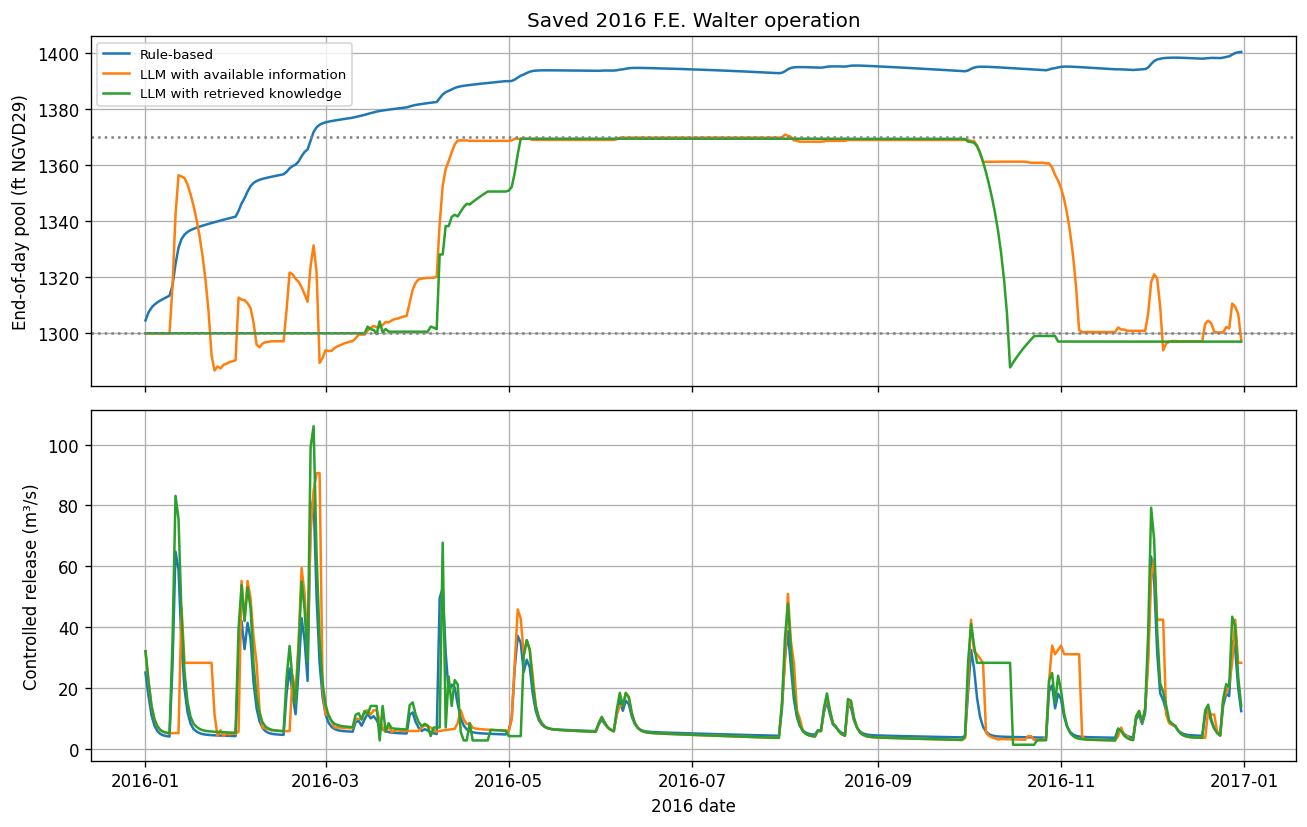

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for method, group in comparison.groupby("method label", sort=False):
    dates = pd.to_datetime(group["date"])
    axes[0].plot(dates, group["pool_elevation_end_ft"], label=method)
    axes[1].plot(dates, group["controlled_release_cms"], label=method)
axes[0].axhline(1300, color="gray", linestyle=":")
axes[0].axhline(1370, color="gray", linestyle=":")
axes[0].set(ylabel="End-of-day pool (ft NGVD29)", title="Saved 2016 F.E. Walter operation")
axes[1].set(ylabel="Controlled release (m³/s)", xlabel="2016 date")
axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout()
export = ROOT / "tutorials/assets/fe_walter_three_method.png"
export.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(export, dpi=160, bbox_inches="tight", metadata={"Software": "HydroOpsLM tutorial"})
display(fig)

## 5. Read completion, physics and operating outcomes separately

The saved comparison records 366 completed days and 366 actual HTTP attempts
for each LLM arm, with no retry or fallback. The table reports the saved
seasonal end-pool checks for each engine. Winter means November 1–March 14,
within 1297–1303 ft. Completion and water balance do not establish acceptable
operation: read the November 1 and seasonal results alongside the trajectories.

Independent replies at temperature 0.7 can produce different trajectories.
The same-reply replay in the saved summary isolates engineering equivalence.

In [7]:
rows = []
for name, arm in summary["arms"].items():
    engine, slug = name.split("-", 1)
    compliance = arm["seasonal_end_pool_compliance"]
    rows.append({"method": labels[slug], "engine": engine,
                 "completed days": arm["completed_days"], "actual HTTP attempts": arm["http_attempts"],
                 "winter compliant days": compliance["winter"]["compliant_days"],
                 "winter days": compliance["winter"]["days"],
                 "November 1 end pool (ft)": compliance["november_1_end_pool_ft"],
                 "saved max balance residual (m³)": arm["max_mass_balance_residual_m3"]})
display(pd.DataFrame(rows))
current_balance = (daily["storage_end_m3"] - daily["storage_start_m3"]
                   - (daily["inflow_cms"] - daily["controlled_release_cms"] - daily["spill_cms"]) * 86400)
display(pd.DataFrame([{"check": "current arithmetic recheck of saved CSV water balance",
                       "max absolute residual (m³)": current_balance.abs().max(),
                       "saved rows checked": len(daily)}]))
display(pd.DataFrame([{"method": labels[slug],
                      "exact native requests replayed": values["same_real_reply_replay"]["native_payloads_exact"],
                      "exact framework requests replayed": values["same_real_reply_replay"]["framework_payloads_exact"]}
                     for slug, values in summary["comparisons"].items()]))

,method,engine,completed days,actual HTTP attempts,winter compliant days,winter days,November 1 end pool (ft),saved max balance residual (m³)
0,LLM with available information,original,366,366,63,135,1366.871457,0.0
1,LLM with available information,framework,366,366,61,135,1351.788754,0.0
2,LLM with retrieved knowledge,original,366,366,132,135,1298.604222,0.0
3,LLM with retrieved knowledge,framework,366,366,135,135,1297.055796,0.0


,check,max absolute residual (m³),saved rows checked
0,current arithmetic recheck of saved CSV water balance,9.596698e-08,1464


,method,exact native requests replayed,exact framework requests replayed
0,LLM with available information,366,366
1,LLM with retrieved knowledge,366,366


## Optional new execution

The notebook never executes the commands below. Keep an experiment copy beside
its source, choose a new `run_id` and `output`, and review the model profile.
`check` is offline; `prepare` computes hydrology, unless verified preparation is
explicitly reused. Only the LLM `run` requests decisions with `--allow-network`.

```powershell
Copy-Item examples/fe_walter/coupled/current/llm_available.yaml examples/fe_walter/coupled/current/my-run.yaml
# Edit my-run.yaml: choose a new run_id and output.
reservoir-experiment check examples/fe_walter/coupled/current/my-run.yaml
reservoir-experiment prepare examples/fe_walter/coupled/current/my-run.yaml
reservoir-experiment run examples/fe_walter/coupled/current/my-run.yaml --allow-network
reservoir-experiment verify <new-output-path>/operation
```

For LLM with retrieved knowledge, copy `current/llm_knowledge.yaml` instead.

[Full configuration and audit/trace walkthrough](fe_walter.md) ·
[Saved comparison summary](../examples/fe_walter/coupled/outputs/gemma4_2016_comparison/summary.json) ·
[Recorded available-information pair](../examples/fe_walter/coupled/outputs/gemma4_2016_comparison/llm_available_pair.json) ·
[Recorded retrieved-knowledge pair](../examples/fe_walter/coupled/outputs/gemma4_2016_comparison/llm_knowledge_pair.json)